# Titanic: regressão logística passo a passo

Objetivo: prever quais passageiros sobreviveram ao naufrágio, um problema de classificação binária.

## 1. Exploração dos dados

Antes de modelar, confiro o tamanho dos dados e o tipo de cada coluna.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

KAGGLE_DIR = Path("/kaggle/input/competitions/titanic")
DATA_DIR = KAGGLE_DIR if KAGGLE_DIR.exists() else Path("data")
OUTPUT_DIR = Path("/kaggle/working") if KAGGLE_DIR.exists() else Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

print('train:', train.shape)
print('test:', test.shape)
train.info()

train: (891, 12)
test: (418, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


O `train` tem 891 linhas e 12 colunas. O `test` tem 418 linhas e 11 colunas, porque não traz `Survived`, a coluna que o modelo precisa prever. As colunas de texto (`Name`, `Sex`, `Ticket`, `Cabin` e `Embarked`) vão precisar de tratamento antes do treino.

### Valores nulos

Confiro quantos valores faltam em cada coluna, nos dois arquivos.

In [2]:
pd.DataFrame({'train': train.isnull().sum(), 'test': test.isnull().sum()})

,train,test
Age,177,86.0
Cabin,687,327.0
Embarked,2,0.0
Fare,0,1.0
Name,0,0.0
Parch,0,0.0
PassengerId,0,0.0
Pclass,0,0.0
Sex,0,0.0
SibSp,0,0.0


- **`Cabin`:** falta em 687 linhas do `train` (77%) e 327 do `test` (78%), é o caso mais grave.
- **`Age`:** falta em 177 linhas do `train` (20%) e 86 do `test` (21%), um volume alto demais para descartar as linhas.
- **`Embarked`:** faltam só 2 valores, ambos no `train`.
- **`Fare`:** falta só 1 valor, no `test`.

`Survived` aparece como `NaN` na coluna `test` porque não existe nesse arquivo. O tratamento dos nulos fica para a etapa de pré-processamento.

### Taxa de sobrevivência

Calculo a taxa geral e depois separo por sexo e por classe.

In [3]:
print('Geral:', round(train['Survived'].mean(), 3))
print(train.groupby('Sex')['Survived'].mean().round(3))
print(train.groupby('Pclass')['Survived'].mean().round(3))

Geral: 0.384
Sex
female    0.742
male      0.189
Name: Survived, dtype: float64
Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64


Sobreviveram 38,4% dos passageiros do `train`. A diferença por grupo é grande: 74,2% das mulheres contra 18,9% dos homens, e 63,0% na 1ª classe contra 24,2% na 3ª.

### Gráficos

Os três gráficos comparam a taxa de sobrevivência por sexo, por classe e por faixa de idade.

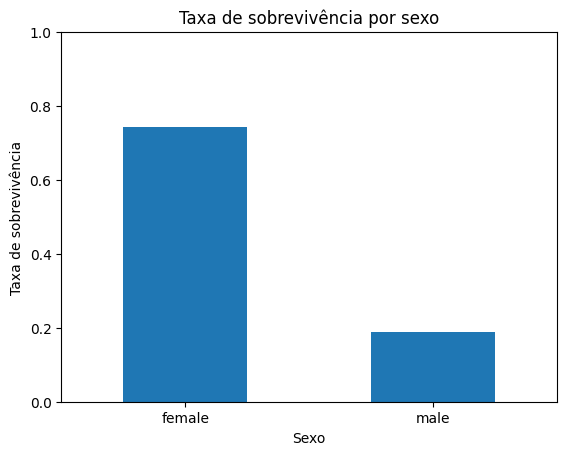

In [4]:
train.groupby('Sex')['Survived'].mean().plot(
    kind='bar', rot=0, ylim=(0, 1),
    title='Taxa de sobrevivência por sexo',
    xlabel='Sexo', ylabel='Taxa de sobrevivência'
)
plt.show()

A taxa de sobrevivência das mulheres é quase 4 vezes a dos homens, o que faz de `Sex` um sinal forte para o modelo e uma boa base para o baseline.

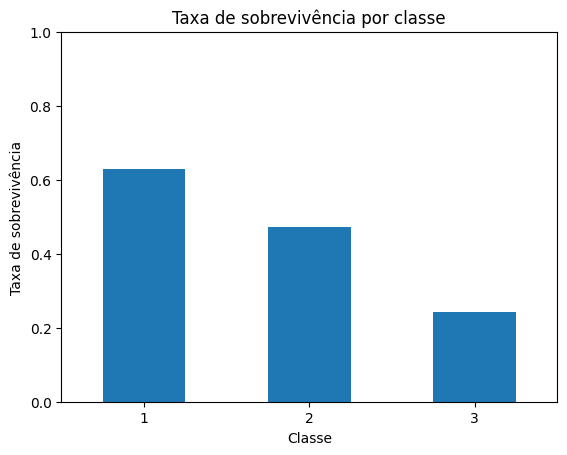

In [5]:
train.groupby('Pclass')['Survived'].mean().plot(
    kind='bar', rot=0, ylim=(0, 1),
    title='Taxa de sobrevivência por classe',
    xlabel='Classe', ylabel='Taxa de sobrevivência'
)
plt.show()

A sobrevivência cai a cada classe: na 1ª ela é cerca de 2,6 vezes a da 3ª, então `Pclass` também deve ajudar o modelo.

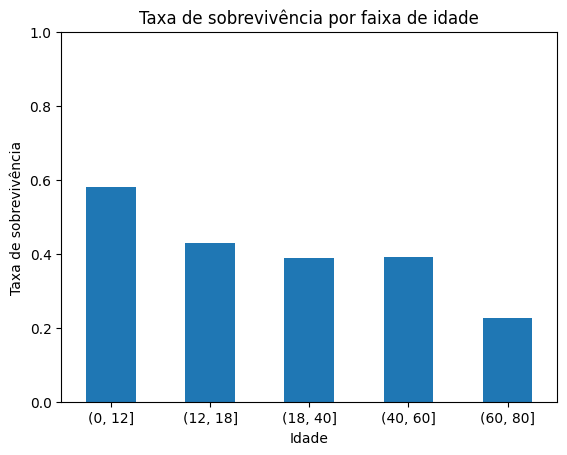

In [6]:
faixas = pd.cut(train['Age'], bins=[0, 12, 18, 40, 60, 80])

train.groupby(faixas, observed=True)['Survived'].mean().plot(
    kind='bar', rot=0, ylim=(0, 1),
    title='Taxa de sobrevivência por faixa de idade',
    xlabel='Idade', ylabel='Taxa de sobrevivência'
)
plt.show()

Crianças de até 12 anos têm a maior taxa (cerca de 58%) e passageiros acima de 60 anos, a menor (cerca de 23%). Entre 18 e 60 anos ela quase não muda, perto de 39%, então a idade parece pesar mais nos extremos. Os 177 passageiros sem `Age` ficam de fora deste gráfico.

## 2. Pré-processamento

O modelo não aceita valores nulos nem texto, então cada coluna precisa de uma decisão.

### Valores nulos

- **`Age`:** mediana. Faltam 20% das linhas, muito para descartar, e a mediana sofre menos com valores extremos do que a média.
- **`Fare`:** mediana, pelo mesmo motivo. Falta só 1 valor, no `test`.
- **`Embarked`:** moda, porque é uma coluna de categorias e faltam só 2 valores.

Calculo essas estatísticas só no `train` e reaplico no `test`. Usar dados do `test` aqui seria vazamento de dados.

In [7]:
print('Age:', train['Age'].median())
print('Fare:', train['Fare'].median())
print('Embarked:', train['Embarked'].mode()[0])

Age: 28.0
Fare: 14.4542
Embarked: S


A mediana de `Age` é 28 anos, a de `Fare` é 14,45 e o porto mais comum é `S`.

### Colunas removidas

Antes de remover as colunas de texto, confiro quantos valores diferentes cada uma tem.

In [8]:
train[['Name', 'Ticket', 'Cabin']].nunique()

Name      891
Ticket    681
Cabin     147
dtype: int64

- **`Name` e `Ticket`:** têm 891 e 681 valores diferentes, quase um por passageiro, então o modelo não consegue generalizar a partir deles como estão.
- **`Cabin`:** falta em 77% das linhas do `train` e tem 147 valores diferentes.
- **`PassengerId`:** só identifica o passageiro. Sai do treino, mas guardo os IDs do `test` para a submissão.

### Conversão em números

- **`Sex`:** mapeamento para 0 (`male`) e 1 (`female`), porque são só duas categorias.
- **`Embarked`:** one-hot, porque não existe ordem entre os portos. O `drop_first` remove a coluna redundante: quem não embarcou em `Q` nem em `S` embarcou em `C`.

In [9]:
passenger_ids = test['PassengerId']

def preparar(df, referencia):
    df = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])
    df['Age'] = df['Age'].fillna(referencia['Age'].median())
    df['Fare'] = df['Fare'].fillna(referencia['Fare'].median())
    df['Embarked'] = df['Embarked'].fillna(referencia['Embarked'].mode()[0])
    df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
    return pd.get_dummies(df, columns=['Embarked'], drop_first=True, dtype=int)

X_train = preparar(train.drop(columns='Survived'), train)
y_train = train['Survived']
X_test = preparar(test, train)

print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('Nulos:', X_train.isnull().sum().sum(), X_test.isnull().sum().sum())
print('Mesmas colunas:', list(X_train.columns) == list(X_test.columns))
print('IDs guardados:', len(passenger_ids))
X_train.head()

X_train: (891, 8)
X_test: (418, 8)
Nulos: 0 0
Mesmas colunas: True
IDs guardados: 418


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,3,0,22.0,1,0,7.2500,0,1
1,1,1,38.0,1,0,71.2833,0,0
2,3,1,26.0,0,0,7.9250,0,1
3,1,1,35.0,1,0,53.1000,0,1
4,3,0,35.0,0,0,8.0500,0,1


`train` e `test` passam pela mesma função, então recebem as mesmas transformações. O parâmetro `referencia` define de onde saem as estatísticas: aqui, sempre do `train`. Os dois ficam com as mesmas 8 colunas e sem nulos, e os IDs dos 418 passageiros do `test` estão guardados para a submissão.

## 3. Baseline e modelo

### Separação de validação

O `test` não tem `Survived`, então separo 20% do `train` para medir o desempenho em dados que o modelo não viu. A separação estratificada mantém a mesma proporção de sobreviventes nas duas partes.

As medianas e a moda vêm só da parte de treino. Assim, a validação não influencia o preparo dos dados e o resultado não fica otimista por vazamento.

In [10]:
from sklearn.model_selection import train_test_split

treino, validacao = train_test_split(
    train, test_size=0.2, stratify=train['Survived'], random_state=42
)

X_treino = preparar(treino.drop(columns='Survived'), treino)
y_treino = treino['Survived']
X_val = preparar(validacao.drop(columns='Survived'), treino)
y_val = validacao['Survived']

print('Treino:', X_treino.shape)
print('Validação:', X_val.shape)
print('Mesmas colunas:', list(X_treino.columns) == list(X_val.columns))
print('Sobrevivência:', round(y_treino.mean(), 3), round(y_val.mean(), 3))

Treino: (712, 8)
Validação: (179, 8)
Mesmas colunas: True
Sobrevivência: 0.383 0.385


São 712 linhas para treino e 179 para validação. A taxa de sobrevivência ficou em 38,3% e 38,5%, o que confirma a estratificação.

### Baseline

Antes do modelo, calculo uma regra simples para comparar: "todas as mulheres sobrevivem". Um modelo só vale a pena se superar essa regra.

In [11]:
from sklearn.metrics import accuracy_score

baseline = (validacao['Sex'] == 'female').astype(int)
acuracia_baseline = accuracy_score(y_val, baseline)

print('Baseline:', round(acuracia_baseline, 3))

Baseline: 0.777


A regra acerta 77,7% da validação (139 de 179). Esse é o número a superar.

### Regressão logística

É um modelo de classificação binária, rápido e interpretável: cada coluna tem um coeficiente que mostra como ela influencia a previsão. O `max_iter=1000` dá ao treino iterações suficientes para convergir.

In [12]:
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_treino, y_treino)

previsoes = modelo.predict(X_val)
acuracia_modelo = accuracy_score(y_val, previsoes)

print('Modelo:', round(acuracia_modelo, 3))
print('Diferença em pontos:', round((acuracia_modelo - acuracia_baseline) * 100, 1))

Modelo: 0.804
Diferença em pontos: 2.8


O modelo acerta 80,4% da validação e supera o baseline em 2,8 pontos: são 144 acertos contra 139, ou 5 passageiros a mais em 179. A vantagem é pequena e vem de uma única separação, então não dá para tratá-la como garantida.

### Matriz de confusão

A acurácia diz quanto o modelo acerta, e a matriz mostra onde ele erra.

In [13]:
from sklearn.metrics import confusion_matrix

pd.DataFrame(
    confusion_matrix(y_val, previsoes),
    index=['Real: morreu', 'Real: sobreviveu'],
    columns=['Previsto: morreu', 'Previsto: sobreviveu']
)

,Previsto: morreu,Previsto: sobreviveu
Real: morreu,98,12
Real: sobreviveu,23,46


O modelo erra mais ao prever quem sobreviveu: dos 35 erros, 23 são sobreviventes previstos como mortos e 12 são o contrário. Ele acerta 89% de quem morreu (98 de 110), mas só 67% de quem sobreviveu (46 de 69).

### Coeficientes

Um coeficiente positivo aumenta a chance prevista de sobreviver, e um negativo diminui.

In [14]:
pd.Series(modelo.coef_[0], index=X_treino.columns).sort_values()

Pclass       -1.093497
Embarked_S   -0.384368
SibSp        -0.245507
Parch        -0.072106
Age          -0.038813
Fare          0.002229
Embarked_Q    0.287802
Sex           2.558710
dtype: float64

Os coeficientes atuam sobre o logaritmo das *odds* (a razão entre a chance de sobreviver e a de não sobreviver). Mantendo as outras colunas iguais:

- **`Sex` (+2,56):** é o maior efeito. Ser mulher multiplica as *odds* por cerca de 13.
- **`Pclass` (−1,09):** cada classe a mais (da 1ª para a 2ª, da 2ª para a 3ª) divide as *odds* por cerca de 3.
- **`Age` (−0,039):** 10 anos a mais reduzem as *odds* em cerca de 32%.
- **`SibSp` (−0,25) e `Parch` (−0,07):** mais familiares a bordo reduzem as *odds*, com efeito bem menor em `Parch`.
- **`Embarked_S` (−0,38) e `Embarked_Q` (+0,29):** a comparação é sempre com o porto `C`, a coluna removida pelo `drop_first`.
- **`Fare` (+0,002):** o valor parece pequeno, mas vale por unidade de tarifa.

As colunas têm escalas diferentes, então o tamanho dos coeficientes não é diretamente comparável entre elas. Eles também mostram associação, não causa.

## 4. Submissão

A validação já cumpriu seu papel de medir o desempenho. Para a previsão final, treino o modelo de novo com as 891 linhas do `train`, porque mais dados tendem a ajudar, e gero o CSV com `PassengerId` e `Survived`.

In [15]:
modelo_final = LogisticRegression(max_iter=1000)
modelo_final.fit(X_train, y_train)

submissao = pd.DataFrame({
    'PassengerId': passenger_ids,
    'Survived': modelo_final.predict(X_test)
})
submissao.to_csv(OUTPUT_DIR / 'submission.csv', index=False)

print('Formato:', submissao.shape)
print(submissao.dtypes)
print(submissao['Survived'].value_counts())
submissao.head()

Formato: (418, 2)
PassengerId    int64
Survived       int64
dtype: object
Survived
0    263
1    155
Name: count, dtype: int64


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


O CSV tem 418 linhas, com `Survived` em 0 ou 1. O modelo prevê 155 sobreviventes (37%), perto dos 38,4% do `train`.

**Score público no leaderboard: 0,76794.** Ele ficou 3,6 pontos abaixo dos 80,4% da validação. A validação tem só 179 passageiros e vem de uma única separação, então essa estimativa pode ter saído otimista. Vou comparar esses números com mais cuidado na etapa de melhoria.

## 5. Melhoria

O primeiro modelo superou o baseline por pouco, então testo colunas novas e outro tipo de modelo.

### Features novas

- **`FamilySize`:** tamanho da família a bordo (`SibSp` + `Parch` + 1).
- **`IsAlone`:** indica quem viajava sem família.
- **`Title`:** título extraído do nome. Ele resume sexo, idade e posição social: `Master`, por exemplo, identifica meninos, algo que `Sex` e `Age` separados captam pior.

Essas colunas são calculadas linha a linha, sem estatísticas de outros passageiros, então não criam risco de vazamento.

Primeiro, confiro quantos passageiros têm cada título.

In [16]:
train['Name'].str.extract(r',\s*([^.]+)\.', expand=False).value_counts()

Name
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Col               2
Mlle              2
Major             2
Ms                1
Mme               1
Don               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

`Mr`, `Miss`, `Mrs` e `Master` somam 864 dos 891 passageiros. Os demais títulos têm poucos casos, então ficam juntos como grupo de referência, sem coluna própria.

In [17]:
def preparar_v2(df, referencia):
    X = preparar(df, referencia)
    X['FamilySize'] = df['SibSp'] + df['Parch'] + 1
    X['IsAlone'] = (X['FamilySize'] == 1).astype(int)
    titulo = df['Name'].str.extract(r',\s*([^.]+)\.', expand=False)
    for nome in ['Mr', 'Mrs', 'Miss', 'Master']:
        X[f'Title_{nome}'] = (titulo == nome).astype(int)
    return X

X_treino_v2 = preparar_v2(treino.drop(columns='Survived'), treino)
X_val_v2 = preparar_v2(validacao.drop(columns='Survived'), treino)

print('X_treino_v2:', X_treino_v2.shape)
print('X_val_v2:', X_val_v2.shape)
print('Nulos:', X_treino_v2.isnull().sum().sum(), X_val_v2.isnull().sum().sum())
X_treino_v2.head()

X_treino_v2: (712, 14)
X_val_v2: (179, 14)
Nulos: 0 0


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S,FamilySize,IsAlone,Title_Mr,Title_Mrs,Title_Miss,Title_Master
692,3,0,28.5,0,0,56.4958,0,1,1,1,1,0,0,0
481,2,0,28.5,0,0,0.0000,0,1,1,1,1,0,0,0
527,1,0,28.5,0,0,221.7792,0,1,1,1,1,0,0,0
855,3,1,18.0,0,1,9.3500,0,1,2,0,0,1,0,0
801,2,1,31.0,1,1,26.2500,0,1,3,0,0,1,0,0


### Novos modelos

A Random Forest combina várias árvores de decisão e consegue captar interações entre colunas, como sexo e classe, sem que eu precise criá-las. O `max_depth=5` limita o tamanho das árvores para reduzir o overfitting.

Mostro a acurácia no treino e na validação porque um treino muito acima da validação é sinal de overfitting.

In [18]:
from sklearn.ensemble import RandomForestClassifier

candidatos = {
    'logistica_features': LogisticRegression(max_iter=1000),
    'random_forest': RandomForestClassifier(n_estimators=300, max_depth=5, random_state=42)
}

print('logistica_original')
print('  Treino:', round(modelo.score(X_treino, y_treino), 3))
print('  Validação:', round(modelo.score(X_val, y_val), 3))

for nome, modelo_v2 in candidatos.items():
    modelo_v2.fit(X_treino_v2, y_treino)
    print(nome)
    print('  Treino:', round(modelo_v2.score(X_treino_v2, y_treino), 3))
    print('  Validação:', round(modelo_v2.score(X_val_v2, y_val), 3))

logistica_original
  Treino: 0.808
  Validação: 0.804
logistica_features
  Treino: 0.829
  Validação: 0.838
random_forest
  Treino: 0.846
  Validação: 0.827


### Previsões para o leaderboard

Como no primeiro modelo, treino cada candidato de novo com as 891 linhas do `train` antes de prever o `test`.

In [19]:
X_train_v2 = preparar_v2(train.drop(columns='Survived'), train)
X_test_v2 = preparar_v2(test, train)

for nome, modelo_v2 in candidatos.items():
    modelo_v2.fit(X_train_v2, y_train)
    previsao = pd.DataFrame({
        'PassengerId': passenger_ids,
        'Survived': modelo_v2.predict(X_test_v2)
    })
    previsao.to_csv(OUTPUT_DIR / f'submission_{nome}.csv', index=False)
    print(nome, previsao.shape, 'sobreviventes:', previsao['Survived'].sum())

logistica_features (418, 2) sobreviventes: 164
random_forest (418, 2) sobreviventes: 165


### Comparação dos modelos

| Modelo | Treino | Validação | Leaderboard |
|---|---|---|---|
| Logística original | 0,808 | 0,804 | 0,76794 |
| Logística com features novas | 0,829 | 0,838 | 0,77511 |
| Random Forest com features novas | 0,846 | 0,827 | 0,77751 |

- **Features novas:** melhoraram a logística na validação e no leaderboard, de 321 para 324 acertos em 418.
- **Melhor modelo:** a Random Forest teve o maior score público, mas só 1 passageiro acima da logística com features (325 contra 324), uma diferença pequena demais para concluir que ela é melhor.

### Validação e leaderboard

Todos os modelos caíram no leaderboard, de 3,6 a 6,3 pontos, e a ordem mudou: a logística com features venceu na validação e a Random Forest, no leaderboard.

Treino e validação ficaram próximos (no máximo 1,9 ponto de diferença), então não há sinal forte de overfitting nos dados de treino. A explicação mais provável é que a validação saiu otimista: são só 179 passageiros, uma única separação e os mesmos dados usados para comparar os modelos. O `test` também pode ter uma composição um pouco diferente, o que não dá para confirmar aqui.

## 6. Conclusão

### O que funcionou

- O preparo dos dados usa estatísticas só da parte de treino, o que evita vazamento na validação.
- As features novas melhoraram a logística no leaderboard, de 0,76794 para 0,77511.
- O melhor score público foi 0,77751, com a Random Forest (325 acertos em 418).
- A análise inicial e os coeficientes apontam `Sex` e `Pclass` como sinais fortes de sobrevivência.

### Limitações

- A validação tem só 179 passageiros e uma única separação. Os três scores públicos ficaram abaixo dela, e ela não acertou a ordem dos modelos.
- A diferença entre os dois melhores modelos é de 1 passageiro, pequena demais para escolher um vencedor.
- A logística original acertou só 67% de quem sobreviveu na validação, apesar dos 80,4% de acurácia.
- `Cabin` foi descartada e `Age` foi preenchida com uma única mediana, o que simplifica informações que podem ser úteis.

### Próximos passos

- Usar validação cruzada para comparar modelos com mais segurança.
- Preencher `Age` por grupo, como título ou classe, em vez de uma mediana geral.
- Extrair o deck, a letra inicial de `Cabin`, tratando os valores ausentes como uma categoria.
- Ajustar hiperparâmetros só depois de ter uma validação mais confiável.

### Créditos

Este notebook foi desenvolvido por mim com apoio do Claude (Anthropic) na escrita do código, analisei e revisei os resultados de cada etapa. Nenhum notebook de terceiros foi usado como base.